# Повышение эффективности методов классификации

Семинарист: [Федорова Валерия Сергеевна](https://www.hse.ru/org/persons/510438167)

Скрипт подготовлен по материалам: [Проворовой (Радыгиной) Анны Александровны](https://www.hse.ru/staff/provorovaaa/)

# Задание: https://disk.360.yandex.ru/i/tjOn-dCan68vWg
Ссылка на данные: https://disk.360.yandex.ru/d/CzqX9FytAo3uHg

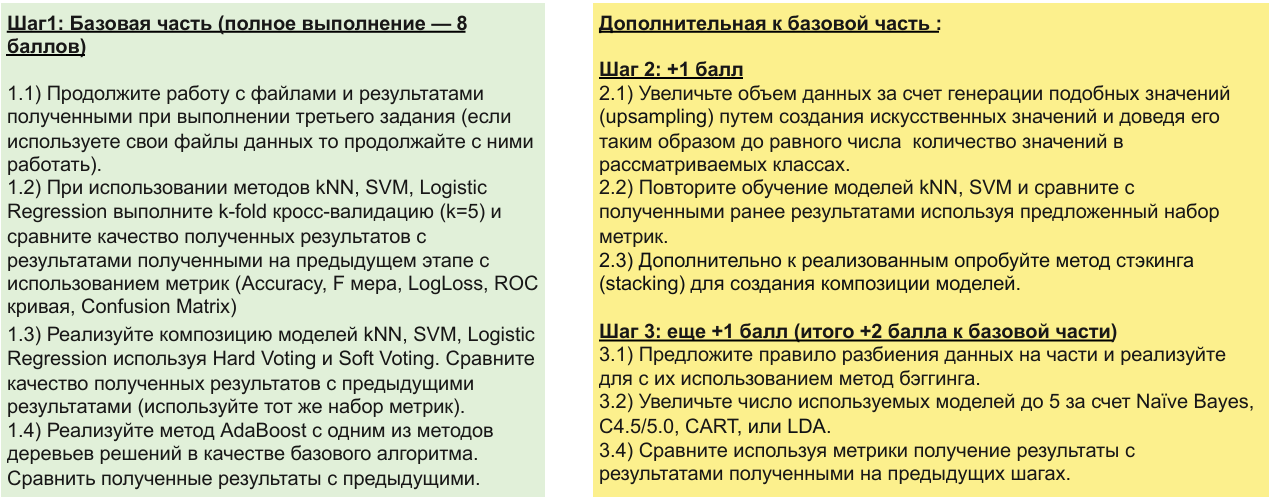

## Загрузка данных

На этом занятии мы будем использовать кросс-секционные данные, то есть наблюдения не будут зависеть друг от друга и от времени.

⚠️ На предыдущих занятиях мы работали с временными рядами. Для них некоторые методы оценки и настройки моделей применяются иначе. Это отдельно рассмотрим в разделе про кросс-валидацию.

In [ ]:
import pandas as pd
import numpy as np

# для примера работы в классе используем предустановленный датасет из sklearn
from sklearn.datasets import load_breast_cancer

# он загружается особым образом. При выполнении задания измените код, чтобы загрузить Ваш датасет
data = load_breast_cancer()
X, y = data.data, data.target

Описание колонок:

| Название признака | Описание |
|-------------------|--------|
| **radius_mean** | Средний радиус (среднее расстояние от центра до точек контура) |
| **texture_mean** | Средняя текстура (стандартное отклонение значений серого) |
| **perimeter_mean** | Средний периметр |
| **area_mean** | Средняя площадь |
| **smoothness_mean** | Средняя гладкость (локальные вариации длины радиуса) |
| **compactness_mean** | Средняя компактность (среднее значение периметр² / площадь – 1) |
| **concavity_mean** | Средняя вогнутость (глубина вогнутых участков контура) |
| **concave points_mean** | Среднее количество вогнутых точек (число вогнутых участков контура) |
| **symmetry_mean** | Средняя симметрия |
| **fractal_dimension_mean** | среднее для «приближения береговой линии» - 1 |
| **radius_se** | стандартная ошибка для среднего значения расстояний от центра до точек на периметре|
| **texture_se** | стандартная ошибка для стандартного отклонения значений шкалы серого |
| **perimeter_se** | Стандартная ошибка периметра |
| **area_se** | Стандартная ошибка площади |
| **smoothness_se** | Стандартная ошибка гладкости |
| **compactness_se** | Стандартная ошибка компактности |
| **concavity_se** | Стандартная ошибка вогнутости |
| **concave points_se** | Стандартная ошибка количества вогнутых точек |
| **symmetry_se** | Стандартная ошибка симметрии |
| **fractal_dimension_se** | Стандартная ошибка для «приближения береговой линии» - 1 |
| **radius_worst** | «наихудшее» или наибольшее среднее значение для среднего расстояния от центра до точек на периметре |
| **texture_worst** | «наихудшее» или наибольшее среднее значение стандартного отклонения значений шкалы серого|
| **perimeter_worst** | Наихудшее значение периметра |
| **area_worst** | Наихудшее значение площади |
| **smoothness_worst** | Наихудшее значение гладкости |
| **compactness_worst** | Наихудшее значение компактности |
| **concavity_worst** | Наихудшее значение вогнутости |
| **concave points_worst** | Наихудшее количество вогнутых точек |
| **symmetry_worst** | Наихудшее значение симметрии |
| **fractal_dimension_worst** | Наихудшее значение фрактального измерения |

**Дополнительно:**
- **Целевая переменная (`target`)**:  
  - `0` — злокачественная опухоль (malignant)  
  - `1` — доброкачественная опухоль (benign)  
- **Число объектов**: 569  
- **Баланс классов**: 212 злокачественных, 357 доброкачественных  
- Все признаки — **вещественные числа**, **без пропусков**

## Разбиваем данные на обучающую и тестовую выборки

shuffle = True - можем перемешивать, потому что данные о разных пациентах не зависят друг от друга и от времени

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=31)

## Масштабируем данные

### Стандартизация признаков

**Стандартизация признаков** — это преобразование данных, при котором каждый признак приводится к нулевому среднему и единичной дисперсии (стандартному отклонению). Формула:  

$$z = \frac{x-μ}{σ}$$

где $x$ — исходное значение признака, $μ$ — среднее значение признака, $σ$ — его стандартное отклонение.

**Зачем это нужно?**
Многие алгоритмы машинного обучения чувствительны к масштабу признаков:

* Методы, основанные на расстояниях (например, kNN, SVM, k-means) могут работать некорректно, если один признак измеряется в тысячах, а другой — в долях.
* Градиентные методы оптимизации (например, в логистической регрессии или нейросетях) сходятся быстрее, когда признаки находятся в сопоставимом диапазоне.
* Регуляризация (L1/L2) штрафует коэффициенты одинаково, поэтому масштаб признаков влияет на силу регуляризации.

**Важные особенности StandardScaler:**
* *Обучается только на обучающей выборке:* среднее и стандартное отклонение вычисляются по трейну, чтобы избежать утечки данных (data leakage).
* *Применяется одинаково ко всем выборкам* (train, validation, test): после fit() на трейне вызывается transform() на всех остальных.
* *Работает только с числовыми признаками;* категориальные признаки должны быть обработаны отдельно.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

## Обучаем модели

Возьмем модели kNN, логистическую регрессию и SVC

### метрика LogLoss

Введём ещё одну метрику качества модели.

**LogLoss (логарифмическая функция потерь)** — это метрика качества, широко используемая в задачах бинарной и многоклассовой классификации, когда модель выдаёт *вероятности принадлежности к классам*, а не просто жёсткие предсказания.

Для бинарной классификации LogLoss вычисляется по формуле:

$\text{LogLoss} = -\frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(p_i) + (1 - y_i) \log(1 - p_i) \right], $  

где:

$y_i$ — истинная метка (0 или 1),

$p_i$ — предсказанная моделью вероятность принадлежности к положительному классу.


| LogLoss | Интерпретация |
|--------|----------------|
| ≈ 0.0  | Идеальная модель |
| ≈ 0.1–0.3 | Очень хорошая модель |
| ≈ 0.3–0.6 | Хорошая / приемлемая модель |
| ≈ 0.693 | Уровень **случайного гадания**: если всегда предсказывать $p_i = 0.5$, то $LogLoss = -log(0.5) \approx 0.693$ |
| > 1.0  | Модель работает **хуже случайного классификатора** или сильно переобучена/недообучена |


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, accuracy_score, auc, accuracy_score, precision_score, recall_score, f1_score, log_loss
import matplotlib.pyplot as plt


# обучение моделей

models = {
    'kNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(probability=True, kernel='linear'),
    'LR': LogisticRegression(max_iter=1000),
}

results = {}
y_probs = {}
y_preds = {}
for name, model in models.items():
    model.fit(x_train_scaled, y_train)
    y_probs[name] = model.predict_proba(x_test_scaled)[:, 1]  # вероятность класса '1'
    y_preds[name] = model.predict(x_test_scaled)
    results[name] = {
        'accuracy': accuracy_score(y_test, y_preds[name]),
        'logloss': log_loss(y_test, y_probs[name]), # тут оцениваются вероятности, а не предсказания класса!
        'precision': precision_score(y_test, y_preds[name]),
        'recall': recall_score(y_test, y_preds[name]),
        'f1': f1_score(y_test, y_preds[name])
    }

pd.DataFrame(results).T.round(4)

,accuracy,logloss,precision,recall,f1
kNN,0.9474,0.1122,0.9296,0.9851,0.9565
SVM,0.9825,0.0866,0.9851,0.9851,0.9851
LR,0.9737,0.0821,0.9848,0.9701,0.9774


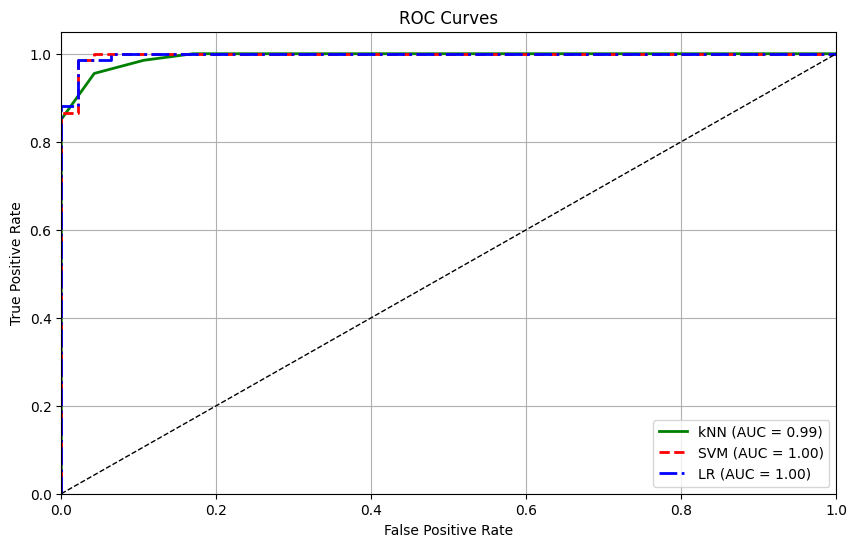

In [ ]:
# Визуализация ROC-кривых
plt.figure(figsize=(10, 6))
colors = {'kNN': 'green', 'SVM': 'red', 'LR': 'blue'}
linestyles = {'kNN': '-', 'SVM': '--', 'LR': '-.'}

for name, prob in y_probs.items():
    fpr, tpr, thresholds = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[name], linestyle=linestyles[name],
             linewidth=2, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=1) # случайный классификатор
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


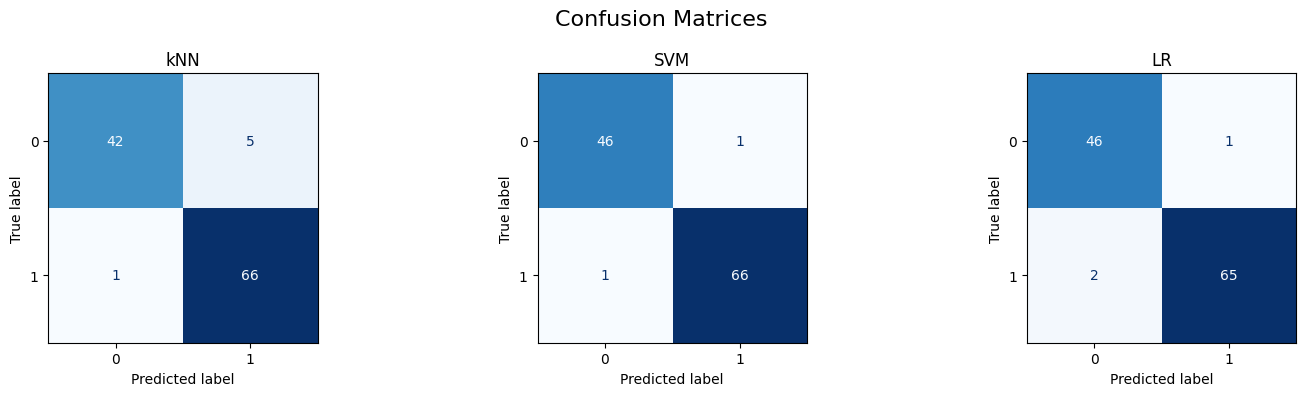

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Визуализация матриц ошибок
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Confusion Matrices', fontsize=16)

for idx, (name, y_pred) in enumerate(y_preds.items()):
    cm = confusion_matrix(y_test, y_preds[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f'{name}')

plt.tight_layout()
plt.show()

## Способы повышения эффективности методов классификации

### Изменения порога классификации

Для бинарной классификации модель может оценивать вероятность принадлежности объекта к классу 1:

$$ p = P(y = 1 | X) $$


По умолчанию большинство классификаторов относят объект к классу 1, если

$$ p \geq 0.5 $$


то есть:

$$ \hat y = \begin{cases} 1,&p\geq 0.5\\ 0,&p<0.5 \end{cases} $$

Но 0.5 — не обязательно оптимальный порог. Таким образом, изменяя порог, мы меняем количество объектов, которые относим к положительному классу.


**Что происходит с Precision и Recall?**

Если снизить порог, модель начинает чаще предсказывать класс 1:
* больше объектов попадет в TP;
* но одновременно может вырасти количество FP;
* обычно Recall увеличивается;
* обычно Precision уменьшается.

Если повысить порог:
* модель становится более «строгой» в отнесении к классу 1;
* уменьшается количество FP;
* но можно пропустить больше объектов класса 1;
* обычно Precision увеличивается;
* обычно Recall уменьшается.

Поэтому выбор порога — это не просто поиск «оптимального значения», а компромисс между разными типами ошибок.

In [ ]:
pd.DataFrame({
    'true_class': y_test[:10],
    'kNN_probability': y_probs['kNN'][:10],
    'SVC_probability': y_probs['SVM'][:10],
    'LR_probability': y_probs['LR'][:10]
})

,true_class,kNN_probability,SVC_probability,LR_probability
0,1,0.8,0.478475,0.428499
1,1,0.8,0.940369,0.954327
2,1,1.0,0.951907,0.969444
3,0,0.4,0.487983,0.481677
4,1,1.0,0.999993,0.999631
5,1,1.0,0.988252,0.992683
6,1,1.0,0.999997,0.999836
7,0,0.0,0.000018,0.000001
8,1,1.0,1.000000,0.999976
9,0,0.6,0.297038,0.406695


In [ ]:
import numpy as np

thresholds = np.linspace(0.01, 0.99, 99)

In [ ]:
precision_values = []
recall_values = []

for threshold in thresholds:
    y_pred = (y_probs['LR'] >= threshold).astype(int)

    precision_values.append(
        precision_score(y_test, y_pred, zero_division=0)
    )

    recall_values.append(
        recall_score(y_test, y_pred, zero_division=0)
    )

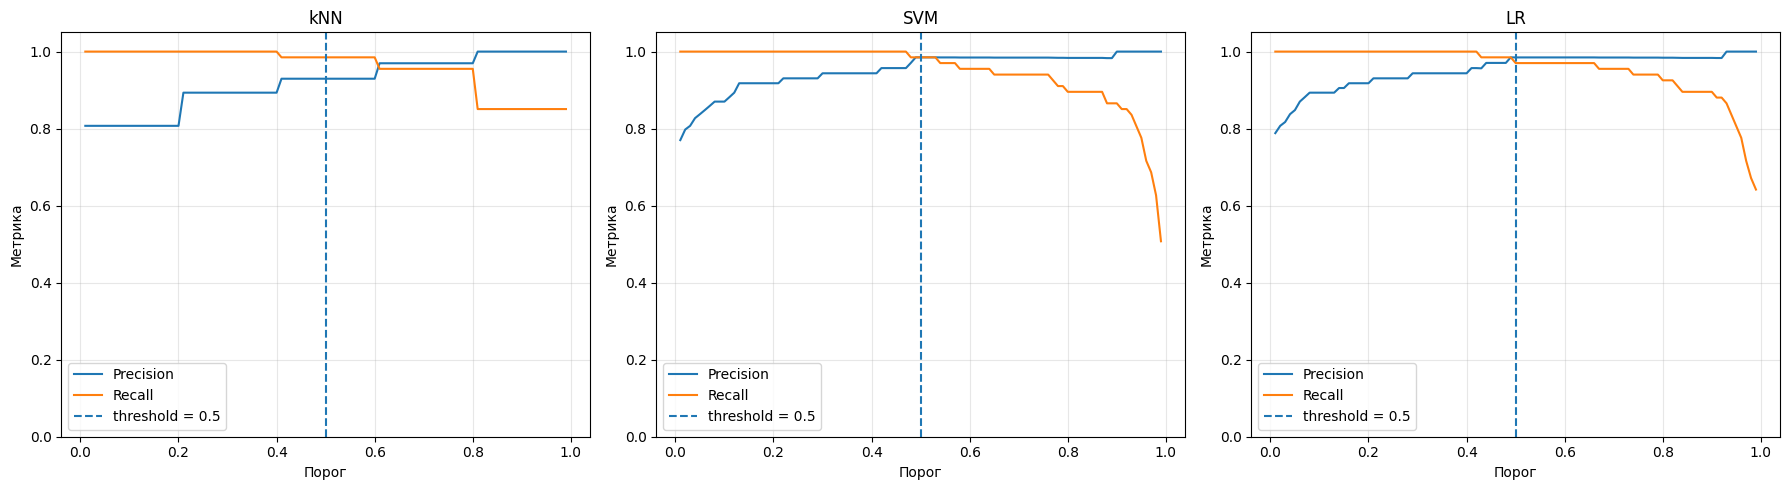

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, probs) in zip(axes, y_probs.items()):

    precision_values = []
    recall_values = []

    for threshold in thresholds:
        y_pred = (probs >= threshold).astype(int)

        precision_values.append(
            precision_score(y_test, y_pred, zero_division=0)
        )
        recall_values.append(
            recall_score(y_test, y_pred, zero_division=0)
        )

    ax.plot(thresholds, precision_values, label='Precision')
    ax.plot(thresholds, recall_values, label='Recall')

    ax.axvline(0.5, linestyle='--', label='threshold = 0.5')

    ax.set_title(name)
    ax.set_xlabel('Порог')
    ax.set_ylabel('Метрика')
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
target_recall = 0.95

results_thresholds = []

for threshold in thresholds:
    y_pred = (y_probs['LR'] >= threshold).astype(int)

    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)

    if recall >= target_recall:
        results_thresholds.append({
            'threshold': threshold,
            'precision': precision,
            'recall': recall
        })

pd.DataFrame(results_thresholds)

,threshold,precision,recall
0,0.01,0.788235,1.000000
1,0.02,0.807229,1.000000
2,0.03,0.817073,1.000000
3,0.04,0.837500,1.000000
4,0.05,0.848101,1.000000
...,...,...,...
68,0.69,0.984615,0.955224
69,0.70,0.984615,0.955224
70,0.71,0.984615,0.955224
71,0.72,0.984615,0.955224


In [ ]:
threshold_df = pd.DataFrame(results_thresholds)

best_threshold = threshold_df.loc[
    threshold_df['precision'].idxmax()
]

best_threshold

,48
threshold,0.490000
precision,0.985075
recall,0.985075


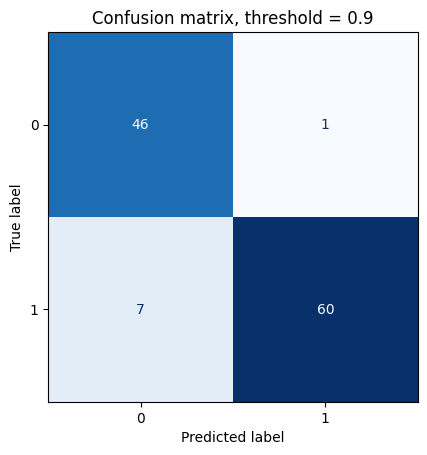

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

threshold = 0.9

y_pred = (y_probs['LR'] >= threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap='Blues',
    colorbar=False
)

plt.title(f'Confusion matrix, threshold = {threshold}')
plt.show()

### Кросс-валидация

До этого момента мы делили выборку на обучащую и тестовую части методом hold-out

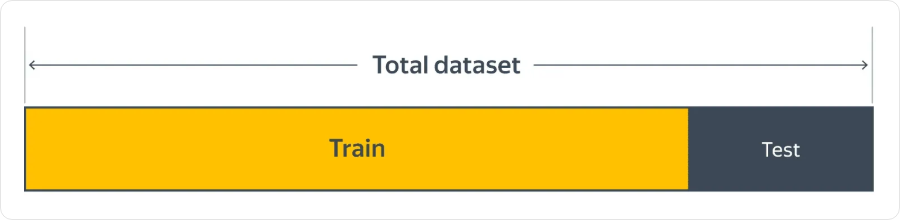

Но оценка метода hold-out зависит от того, как данные разделены на обучающий и тестовый наборы, поэтому мы не можем в полной мере доверять этим оценкам

**Поэтому мы переходим к кросс-валидации**

Кросс-валидация — это техника оценки качества модели машинного обучения, которая позволяет надёжнее оценить её обобщающую способность, особенно когда данных немного. Наиболее популярный вариант — k-фолдовая кросс-валидация (k-fold cross-validation), а при работе с несбалансированными классами часто используют её стратифицированную версию — StratifiedKFold.

Однако важно понимать: кросс-валидация может использоваться в двух разных целях, и от этого зависит, как мы разбиваем данные.

1.  *Кросс-валидация по всей выборке (без отложенного теста)*

Весь датасет используется напрямую в кросс-валидации (например, cross_val_score(..., cv=StratifiedKFold(5)) по всем данным).

Цель получить оценку качества модели, когда нет возможности или необходимости выделять отдельный тестовый набор (например, при очень малом объёме данных или на соревнованиях, где тестовые метки скрыты).

Как это работает:

* Весь датасет разбивается на k стратифицированных фолдов.
* Модель обучается k раз, каждый раз на k-1 фолдах, тестируясь на оставшемся.
* Качество усредняется по всем фолдам → это и есть итоговая оценка.

![image1.png](https://raw.githubusercontent.com/cleanlab/assets/master/cleanlab/pred_probs_cross_val.png)

2. *Кросс-валидация только на тренировочной выборке (для подбора гиперпараметров)*

У нас есть полный датасет, который мы заранее разделили на тренировочную и тестовую части (например, 80/20).

Цель подобрать лучшие гиперпараметры модели (например, k в kNN), не заглядывая в тестовую выборку.

Как это работает:

* Берём только тренировочную часть.
* Для каждого набора гиперпараметров обучаем модель 5 раз, каждый раз на 4 фолдах и проверяя на 1 оставшемся.
* Усредняем метрику (например, accuracy или ROC-AUC) по всем фолдам → получаем оценку качества на трейне.
* Выбираем гиперпараметры с лучшей средней метрикой.
* Обучаем финальную модель на всей тренировочной выборке с выбранными гиперпараметрами.
* Оцениваем её качество на отложенной тестовой выборке — это наша итоговая оценка обобщающей способности.

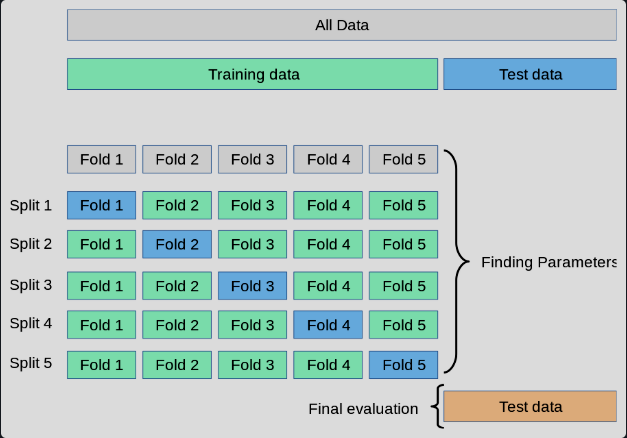

Кросс-валидация дает модели возможность протестировать несколько разбиений, чтобы мы могли получить лучшее представление о том, как модель будет работать на различных данных.

**Важно**: Cross-validation не увеличивает объем данных. Одни и те же наблюдения используются для обучения и проверки на разных итерациях, но каждое конкретное наблюдение не используется одновременно для обучения и проверки в рамках одной итерации.

| Что делаем | Для чего |
|-------------------|--------|
| **Hold-out** | Быстро оценить модель на одном разбиении |
| **Cross-validation** | Получить более устойчивую оценку качества |
| **GridSearch / RandomSearch + CV** | Выбрать гиперпараметры |
| **Test set** | Получить финальную независимую оценку |

**Cross-validation сама по себе не является методом повышения качества модели. Она помогает надежнее оценивать модели и выбирать их параметры.**

Почитать подробнее о кросс-валидации:

* https://neerc.ifmo.ru/wiki/index.php?title=%D0%9A%D1%80%D0%BE%D1%81%D1%81-%D0%B2%D0%B0%D0%BB%D0%B8%D0%B4%D0%B0%D1%86%D0%B8%D1%8F
* https://academy.yandex.ru/handbook/ml/article/kross-validaciya

Почитать подробнее о подборе гиперпараметров с помощью Grid Search и Random Search: https://contest.yandex.ru/tracks/ml/model-evaluation/hyperparameter-tuning

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import StratifiedKFold

scaler = StandardScaler()
x_scaled = scaler.fit_transform(X)

cv = StratifiedKFold() # сохраняет пропорции классов в фолдах

for name, model in models.items():
    # Получаем предсказания на всей выборке через CV
    y_pred_cv = cross_val_predict(model, x_scaled, y, cv=cv, method='predict')
    y_proba_cv = cross_val_predict(model, x_scaled, y, cv=cv, method='predict_proba')[:, 1]

    results[f'{name}_cv'] = {
        'accuracy': accuracy_score(y, y_pred_cv),
        'logloss': log_loss(y, y_proba_cv),
        'precision': precision_score(y, y_pred_cv),
        'recall': recall_score(y, y_pred_cv),
        'f1': f1_score(y, y_pred_cv)
    }

pd.DataFrame(results).T.round(4)

,accuracy,logloss,precision,recall,f1
kNN,0.9474,0.1122,0.9296,0.9851,0.9565
SVM,0.9825,0.0866,0.9851,0.9851,0.9851
LR,0.9737,0.0821,0.9848,0.9701,0.9774
kNN_cv,0.9649,0.1994,0.9616,0.9832,0.9723
SVM_cv,0.9701,0.0992,0.9670,0.9860,0.9764
LR_cv,0.9807,0.0798,0.9779,0.9916,0.9847


In [ ]:
# можем посмотреть на рассчёт метрики (accuracy) по фолдам, какие получаются значения на каждом фолде

from sklearn.model_selection import cross_val_score
import numpy as np

knn_model_cv = KNeighborsClassifier(n_neighbors=5)
knn_cv_scores = cross_val_score(knn_model_cv, x_scaled, y, cv=5)
print('--------------kNN---------------')
print(knn_cv_scores)
print(f'kNN cv_scores mean:{np.mean(knn_cv_scores)}')

svm_model_cv = SVC(probability=True, kernel="linear")
svm_cv_scores = cross_val_score(svm_model_cv, x_scaled, y, cv=5)
print('--------------SVM---------------')
print(svm_cv_scores)
print(f'SVM cv_scores mean:{np.mean(svm_cv_scores)}')

LR_model_cv = LogisticRegression()
LR_cv_scores = cross_val_score(LR_model_cv, x_scaled, y, cv=5)
print('-----------Logistic Regression------------')
print(LR_cv_scores)
print(f'Logistic Regression cv_scores mean:{np.mean(LR_cv_scores)}')

#### Подбор гиперпараметра - количества соседей для kNN.

При построении нашей первоначальной модели k-NN мы установили параметр n_neighbors равным 5 в качестве отправной точки без какой-либо реальной логики в этом выборе.
Мы воспользуемся *GridSearchCV*, чтобы найти оптимальное значение для n_neighbours.

*GridSearchCV* работает путем многократного обучения нашей модели по заданному нами диапазону параметров. Таким образом, мы можем протестировать нашу модель с каждым параметром и определить оптимальные значения, чтобы получить результаты с максимальной точностью.

Для нашей модели мы укажем диапазон значений n_neighbors, чтобы увидеть, какое значение лучше всего подходит для нашей модели. Для этого мы создадим словарь, установив в качестве ключа «n_neighbors» и используя numpy для создания массива значений от 1 до 20.

In [ ]:
from sklearn.model_selection import GridSearchCV

knn_model_2 = KNeighborsClassifier()
param_grid = {'n_neighbors': np.arange(1, 21)}
knn_gscv = GridSearchCV(knn_model_2, param_grid, cv=5)
knn_gscv.fit(x_scaled, y)
# проверим, какой параметр оказался наилучшим
print('Наилучшее колическтво соседей:', knn_gscv.best_params_['n_neighbors'])
print('Наилучшая accuracy:', knn_gscv.best_score_)

Наилучшее колическтво соседей: 9
Наилучшая accuracy: 0.968390001552554


### Кросс-валидация на временных рядах

Если наблюдения зависят от времени, нельзя допускать, чтобы информация из будущего использовалась для обучения модели при оценке ее качества на прошлом. Для проведения кросс-валидации на временных рядах используется TimeSeriesSplit

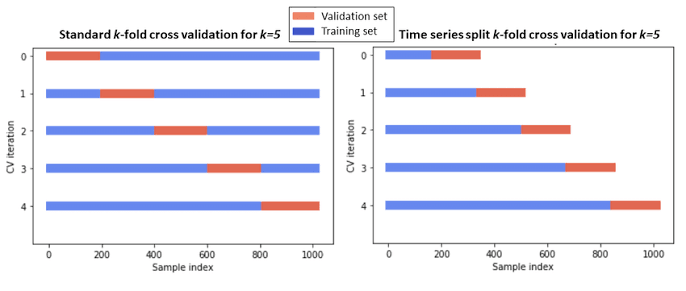

Подробнее про кросс-валидацию на временных рядах и ее реализацию в python: https://habr.com/ru/companies/otus/articles/921604/

### Композиция моделей

![image.png](https://drek4537l1klr.cloudfront.net/serrano/v-15/Figures/image286.png)

В машинном обучении часто оказывается, что несколько слабых или разнообразных моделей вместе работают лучше, чем одна сильная. Такие объединения называются ансамблями (или композициями) моделей.

Основная идея — снизить ошибку за счёт усреднения или комбинирования предсказаний, что позволяет уменьшить как дисперсию (overfitting), так и смещение (bias). Однако это может потребовать больше вычислительных ресурсов и времени на обучение, так как несколько моделей обучаются и объединяются.

**Основные подходы:**

1. *Voting (голосование)* — простейший ансамбль, где несколько моделей «голосуют» за итоговый результат.
* Hard voting: выбирается класс, за который проголосовало большинство (мода).
* Soft voting: усредняются предсказанные вероятности.
2. *Bagging (Bootstrap Aggregating)* — обучение нескольких одинаковых моделей (обычно деревьев) на разных случайных подвыборках даных. Итоговое предсказание получается усреднением (для регрессии) или голосованием (для классификации) по всем моделям.
Пример: Random Forest.
→ Снижает дисперсию, устойчив к переобучению.
3. *Boosting* — последовательное обучение слабых моделей, где каждая следующая фокусируется на ошибках предыдущих.
Примеры: AdaBoost, Gradient Boosting, XGBoost, LightGBM.
→ Снижает смещение и часто даёт высокую точность.
4. *Stacking (стекинг)* — мета-ансамбль, в котором предсказания базовых моделей используются как признаки для мета-модели, которая делает финальное предсказание.
→ Позволяет гибко комбинировать разнородные модели.


In [ ]:
from sklearn.ensemble import VotingClassifier

# Инициализация базовых моделей
knn = KNeighborsClassifier(n_neighbors=9)
svm = SVC(probability=True, random_state=42)  # probability=True для Soft Voting
lr = LogisticRegression(max_iter=1000, random_state=42)


# Hard Voting и Soft Voting
voting_hard = VotingClassifier(
    estimators=[('knn', knn), ('svm', svm), ('lr', lr)],
    voting='hard'
)

voting_soft = VotingClassifier(
    estimators=[('knn', knn), ('svm', svm), ('lr', lr)],
    voting='soft'
)

voting_hard.fit(x_train_scaled, y_train)
voting_soft.fit(x_train_scaled, y_train)

# Оценка ансамблей
y_pred_hard = voting_hard.predict(x_test_scaled)
y_pred_soft = voting_soft.predict(x_test_scaled)
y_pred_soft_proba = voting_soft.predict_proba(x_test_scaled)

results['Hard Voting'] = {
        'accuracy': accuracy_score(y_test, y_pred_hard),
        'precision': precision_score(y_test, y_pred_hard),
        'recall': recall_score(y_test, y_pred_hard),
        'f1': f1_score(y_test, y_pred_hard)
    }
results['Soft Voting'] = {
        'accuracy': accuracy_score(y_test, y_pred_soft),
        'logloss': log_loss(y_test, y_pred_soft_proba),
        'precision': precision_score(y_test, y_pred_soft),
        'recall': recall_score(y_test, y_pred_soft),
        'f1': f1_score(y_test, y_pred_soft)
    }

# Преобразование в DataFrame
pd.DataFrame(results).T.round(4)

,accuracy,logloss,precision,recall,f1
kNN,0.9474,0.1122,0.9296,0.9851,0.9565
SVM,0.9825,0.0866,0.9851,0.9851,0.9851
LR,0.9737,0.0821,0.9848,0.9701,0.9774
kNN_cv,0.9649,0.1994,0.9616,0.9832,0.9723
SVM_cv,0.9701,0.0992,0.9670,0.9860,0.9764
LR_cv,0.9807,0.0798,0.9779,0.9916,0.9847
Hard Voting,0.9825,NaN,0.9710,1.0000,0.9853
Soft Voting,0.9912,0.0909,0.9853,1.0000,0.9926


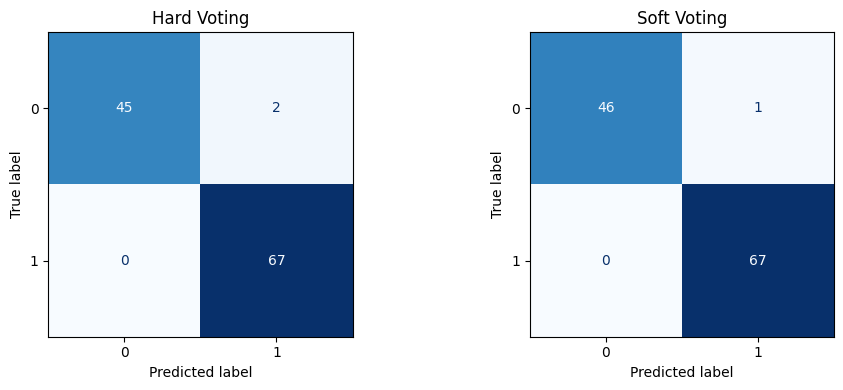

In [ ]:
# Вывод матриц ошибок

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_hard,
    ax=axes[0],
    cmap='Blues',
    colorbar=False
)
axes[0].set_title('Hard Voting')

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_soft,
    ax=axes[1],
    cmap='Blues',
    colorbar=False
)
axes[1].set_title('Soft Voting')

plt.tight_layout()
plt.show()

### AdaBoost (Adaptive Boosting)

AdaBoost (Adaptive Boosting) — это один из первых и наиболее популярных алгоритмов бустинга, предложенный Йоавом Фройндом и Робертом Шапиро в 1996 году. Основная идея метода заключается в последовательном обучении слабых моделей (обычно это простые деревья решений глубины 1 — «стампы»), где *каждая следующая модель уделяет больше внимания объектам, которые предыдущие модели классифицировали с ошибкой*. Для этого после каждой итерации пересчитываются веса обучающих примеров: **ошибочные примеры получают больший вес, а правильно классифицированные — меньший**. В итоге финальное предсказание формируется как взвешенное голосование всех слабых моделей.

**Преимущества AdaBoost**
* *Простота и интерпретируемость:* легко реализуется и понимается; использует интуитивную идею «обрати внимание на ошибки».
* *Высокая точность:* даже с очень простыми (слабыми) базовыми моделями часто достигает отличного качества.
* *Не требует настройки признаков:* автоматически выделяет наиболее информативные признаки через веса.
* *Универсальность:* может работать с любым алгоритмом, способным выступать в роли слабого классификатора (чаще всего — деревья решений).

**Ограничения AdaBoost**
* *Чувствительность к шуму и выбросам:* поскольку алгоритм усиливает вес ошибочно классифицированных объектов, выбросы могут сильно исказить обучение.
* *Склонность к переобучению:* особенно при большом числе базовых моделей или на зашумлённых данных.
* *Требует слабых, но чуть лучше случайного классификатора:* если базовая модель хуже случайного гадания, AdaBoost не сработает.
* *Последовательное обучение:* модели обучаются строго по порядку, что не позволяет эффективно распараллеливать процесс.
* *Зависимость от качества базового алгоритма:* при неудачном выборе слабого ученика результат может быть нестабильным.

### Несколько слов о деревьях решений:

Дерево решений — классификатор, построенный на основе решающих правил вида «если, то», упорядоченных в древовидную иерархическую структуру.

В основе работы дерева решений лежит процесс рекурсивного разбиения исходного множества объектов на подмножества, ассоциированные с предварительно заданными классами. Разбиение производится с помощью решающих правил, в которых осуществляется проверка значений атрибутов по заданному условию.

Подробнее о деревьях решений: https://academy.yandex.ru/handbook/ml/article/reshayushchiye-derevya

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=1, random_state=42)  # слабый ученик для AdaBoost

adaboost = AdaBoostClassifier(
    estimator=dt,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

adaboost.fit(x_train_scaled, y_train)
y_pred = adaboost.predict(x_test_scaled)
y_pred_proba = adaboost.predict_proba(x_test_scaled)

results['Adaboost'] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'logloss': log_loss(y_test, y_pred_proba),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred)
    }

# Преобразование в DataFrame
pd.DataFrame(results).T.round(4)

,accuracy,logloss,precision,recall,f1
kNN,0.9474,0.1122,0.9296,0.9851,0.9565
SVM,0.9825,0.0866,0.9851,0.9851,0.9851
LR,0.9737,0.0821,0.9848,0.9701,0.9774
kNN_cv,0.9649,0.1994,0.9616,0.9832,0.9723
SVM_cv,0.9701,0.0992,0.9670,0.9860,0.9764
LR_cv,0.9807,0.0798,0.9779,0.9916,0.9847
Hard Voting,0.9825,NaN,0.9710,1.0000,0.9853
Soft Voting,0.9912,0.0909,0.9853,1.0000,0.9926
Adaboost,0.9649,0.4124,0.9846,0.9552,0.9697


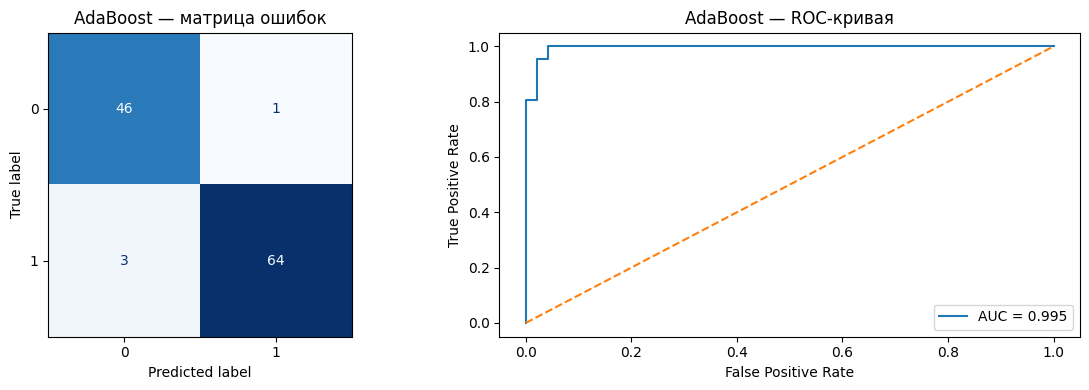

In [ ]:
# Добавьте в визуализацию ROC-кривую и матрицу ошибок

from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Матрица ошибок
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    ax=axes[0],
    cmap='Blues',
    colorbar=False
)
axes[0].set_title('AdaBoost — матрица ошибок')

# ROC-кривая
fpr, tpr, _ = roc_curve(y_test, y_pred_proba[:, 1])
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
axes[1].plot([0, 1], [0, 1], linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('AdaBoost — ROC-кривая')
axes[1].legend()

plt.tight_layout()
plt.show()

## Хакатоны:

Альфа банк: https://alfabank.sale/alfafuture/event/hack/?utm_source=7&utm_medium=3&utm_campaign=2 (прием заявок до 18 октября)

По поводу выбора трека, который подходит для закрытия исследовательского задания в формуле оценки, посоветуйтесь с Леонидом Александровичем